In [19]:
import pandas as pd
import numpy as np

In [6]:
df = pd.read_csv("Exxonmobil Holdings (XOM) Historical Data.csv")

In [7]:
df

,Date,Price,Open,High,Low,Vol.,Change %
0,29/09/2026,161.35,160.22,161.96,159.27,9.16M,-0.72%
1,28/09/2026,162.52,162.80,163.54,161.05,12.81M,1.20%
2,25/09/2026,160.59,160.23,161.79,159.78,11.00M,-0.96%
3,24/09/2026,162.14,163.05,164.91,161.20,12.48M,0.56%
4,23/09/2026,161.23,159.62,162.12,159.42,12.58M,1.59%
...,...,...,...,...,...,...,...
2528,07/09/2016,88.24,88.65,88.67,87.97,7.47M,-0.37%
2529,06/09/2016,88.57,87.84,88.64,87.66,9.85M,1.32%
2530,02/09/2016,87.42,87.42,87.58,86.93,7.10M,0.67%
2531,01/09/2016,86.84,86.72,86.84,86.09,8.43M,-0.34%


In [12]:
df.isna().sum()

Date        0
Price       0
Open        0
High        0
Low         0
Vol.        0
Change %    0
dtype: int64

In [21]:
df['Date'] = pd.to_datetime(df['Date'])

/tmp/ipykernel_95786/2394721818.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


In [22]:
df.sort_values(by="Date", ascending=True)

,Date,Price,Open,High,Low,Vol.,Change %
2532,2016-08-31,87.14,87.14,87.21,86.22,12.49M,-0.43%
2531,2016-09-01,86.84,86.72,86.84,86.09,8.43M,-0.34%
2530,2016-09-02,87.42,87.42,87.58,86.93,7.10M,0.67%
2529,2016-09-06,88.57,87.84,88.64,87.66,9.85M,1.32%
2528,2016-09-07,88.24,88.65,88.67,87.97,7.47M,-0.37%
...,...,...,...,...,...,...,...
4,2026-09-23,161.23,159.62,162.12,159.42,12.58M,1.59%
3,2026-09-24,162.14,163.05,164.91,161.20,12.48M,0.56%
2,2026-09-25,160.59,160.23,161.79,159.78,11.00M,-0.96%
1,2026-09-28,162.52,162.80,163.54,161.05,12.81M,1.20%


In [23]:
df = df.sort_values("Date").reset_index(drop=True)

In [26]:
print("Number of rows:", len(df))
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
print("Duplicate rows:", df.duplicated().sum())

Number of rows: 2533
First date: 2016-08-31 00:00:00
Last date: 2026-09-29 00:00:00
Duplicate rows: 0


In [ ]:
Data Cleaning log

In [27]:
print("Company: ExxonMobil Holdings Corporation ")
print("Ticker: XOM")
print("Exchange: NYSE")
print("Currency/unit: USD")
print("First trading date:", df["Date"].min())
print("Last trading date:", df["Date"].max())
print("Number of observations:", len(df))

Company: ExxonMobil Holdings Corporation 
Ticker: XOM
Exchange: NYSE
Currency/unit: USD
First trading date: 2016-08-31 00:00:00
Last trading date: 2026-09-29 00:00:00
Number of observations: 2533


/usr/local/lib/python3.12/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


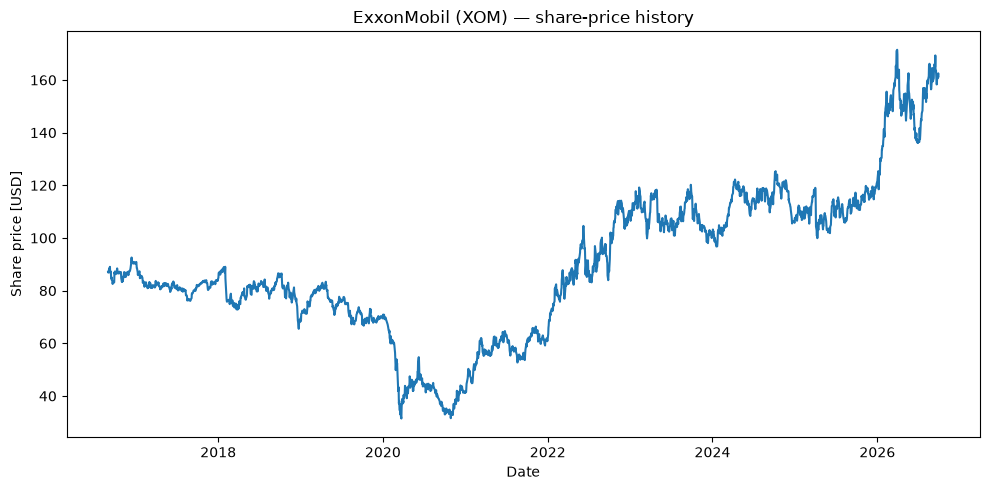

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["Date"], df["Price"])
ax.set_xlabel("Date")
ax.set_ylabel("Share price [USD]")  # Exxon trades in US Dollars
ax.set_title("ExxonMobil (XOM) — share-price history")
plt.tight_layout()
plt.show()

In [30]:
r = 0.0375
T = 2 / 12

df['Forward_Price'] = df['Price'] * np.exp(r * T)

In [34]:
latest_row = df.iloc[-1]
latest_row

Date             2026-09-29 00:00:00
Price                         161.35
Open                          160.22
High                          161.96
Low                           159.27
Vol.                           9.16M
Change %                      -0.72%
Forward_Price             162.361595
Name: 2532, dtype: object

In [35]:
S_0 = latest_row["Price"]
date_S0 = latest_row["Date"]

print(f"S_0 = {S_0}")
print(f"Date of S_0 = {date_S0}")
print("Price unit/currency = USD")

S_0 = 161.35
Date of S_0 = 2026-09-29 00:00:00
Price unit/currency = USD


In [39]:
F0T = S_0 * np.exp(r*T)
print("Spot price =", S_0)
print("Forward price =", F0T)


Spot price = 161.35
Forward price = 162.361595442807


In [40]:
growth_factor = np.exp(r*T)
print(growth_factor)

1.006269572003762


In [42]:
df['Log_Return'] = np.log(df['Price'] / df['Price'].shift(1))
df

,Date,Price,Open,High,Low,Vol.,Change %,Forward_Price,Log_Return
0,2016-08-31,87.14,87.14,87.21,86.22,12.49M,-0.43%,87.686331,NaN
1,2016-09-01,86.84,86.72,86.84,86.09,8.43M,-0.34%,87.384450,-0.003449
2,2016-09-02,87.42,87.42,87.58,86.93,7.10M,0.67%,87.968086,0.006657
3,2016-09-06,88.57,87.84,88.64,87.66,9.85M,1.32%,89.125296,0.013069
4,2016-09-07,88.24,88.65,88.67,87.97,7.47M,-0.37%,88.793227,-0.003733
...,...,...,...,...,...,...,...,...,...
2528,2026-09-23,161.23,159.62,162.12,159.42,12.58M,1.59%,162.240843,0.015753
2529,2026-09-24,162.14,163.05,164.91,161.20,12.48M,0.56%,163.156548,0.005628
2530,2026-09-25,160.59,160.23,161.79,159.78,11.00M,-0.96%,161.596831,-0.009606
2531,2026-09-28,162.52,162.80,163.54,161.05,12.81M,1.20%,163.538931,0.011947


In [48]:
df['Daily_Return'] = df['Price'].pct_change()
returns_clean = df['Daily_Return'].dropna()


Text(0.5, 1.0, 'ExxonMobil (XOM) — Daily Return')

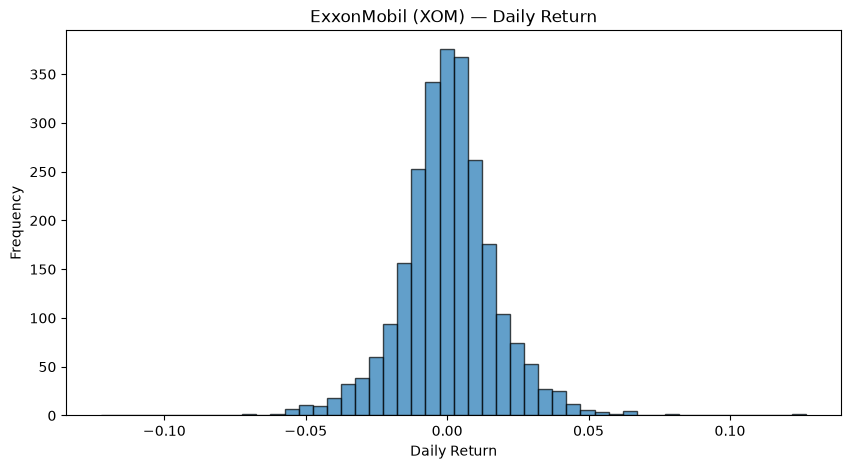

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(returns_clean, bins=50, edgecolor="black", alpha=0.7)

ax.set_xlabel("Daily Return")
ax.set_ylabel("Frequency")
ax.set_title("ExxonMobil (XOM) — Daily Return")